My goal in this project is to investigate whether the sensitivity of cancer cell lines to a drug (ulixertinib) can be predicted using machine learning models from multiple biological features. This was formulated as a binary classification task, with cell lines being classified as either sensitive or resistant to a drug. This was derived from the LN_IC50 values (the target variable). 

This would have extremely useful applications in the field of precision medicine, as having insight on whether a drug is going to be effective for a specific patient before it is used would prevent time and money being wasted on ineffective treatment and likely improve patient prognosis by allowing the most optimal course of action to be taken.  

Due to time constraints and for the simplicity of any conclusions, I only investigated a single drug in this project. Extending this to compare drugs in the dataset could be a good direction for further research. 

In [42]:
### Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score
from scipy.stats import ttest_rel

In [43]:
### Reading In The Data (CSV file)

df = pd.read_csv("GDSC_DATASET.csv") # Relative pathname used- data file must be in same directory as notebook and is included with submission.

In [44]:
### Initial Inspection 

df.head()

,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,LN_IC50,AUC,Z_SCORE,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY
0,683667,PFSK-1,MB,1003,Camptothecin,-1.463887,0.930220,0.433123,nervous_system,medulloblastoma,MB,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
1,684057,ES5,UNCLASSIFIED,1003,Camptothecin,-3.360586,0.791072,-0.599569,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
2,684059,ES7,UNCLASSIFIED,1003,Camptothecin,-5.044940,0.592660,-1.516647,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
3,684062,EW-11,UNCLASSIFIED,1003,Camptothecin,-3.741991,0.734047,-0.807232,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
4,684072,SK-ES-1,UNCLASSIFIED,1003,Camptothecin,-5.142961,0.582439,-1.570016,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Semi-Adherent,Y,Y,Y,TOP1,DNA replication


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242035 entries, 0 to 242034
Data columns (total 19 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   COSMIC_ID                                242035 non-null  int64  
 1   CELL_LINE_NAME                           242035 non-null  object 
 2   TCGA_DESC                                240968 non-null  object 
 3   DRUG_ID                                  242035 non-null  int64  
 4   DRUG_NAME                                242035 non-null  object 
 5   LN_IC50                                  242035 non-null  float64
 6   AUC                                      242035 non-null  float64
 7   Z_SCORE                                  242035 non-null  float64
 8   GDSC Tissue descriptor 1                 232669 non-null  object 
 9   GDSC Tissue descriptor 2                 232669 non-null  object 
 10  Cancer Type (matching TCGA label

In [46]:
df.isnull().sum() # Checking for any missing values in the DataFrame. None are found for the target variable. 

COSMIC_ID                                      0
CELL_LINE_NAME                                 0
TCGA_DESC                                   1067
DRUG_ID                                        0
DRUG_NAME                                      0
LN_IC50                                        0
AUC                                            0
Z_SCORE                                        0
GDSC Tissue descriptor 1                    9366
GDSC Tissue descriptor 2                    9366
Cancer Type (matching TCGA label)          51446
Microsatellite instability Status (MSI)    12353
Screen Medium                               9366
Growth Properties                           9366
CNA                                         9366
Gene Expression                             9366
Methylation                                 9366
TARGET                                     27155
TARGET_PATHWAY                                 0
dtype: int64

The data file was also manually inspected. 

In [47]:
df['DRUG_NAME'].value_counts() # Checking how much data is available for the drugs. Ulixertinib has the most data available and therefore might be a good drug to go with to train robust models.

DRUG_NAME
Ulixertinib       1698
Oxaliplatin       1684
Fulvestrant       1680
Selumetinib       1666
Dactinomycin      1659
                  ... 
IOX2               225
CHIR-99021         225
SL0101             225
CCT-018159         225
Piperlongumine     225
Name: count, Length: 286, dtype: int64

In [48]:
df_ulixertinib = df[df['DRUG_NAME'] == 'Ulixertinib'].copy() # Creating a separate provisional DataFrame for only samples of Ulixertinib.

In [49]:
### Testing Ulixertinib

df_ulixertinib.shape # Verifying it was created successfully and looks correct. 

(1698, 19)

In [50]:
df_ulixertinib['LN_IC50'].describe()

count    1698.000000
mean        2.546608
std         1.501278
min        -2.863156
25%         1.609513
50%         2.676538
75%         3.551869
max         7.283865
Name: LN_IC50, dtype: float64

<Axes: xlabel='LN_IC50', ylabel='Count'>

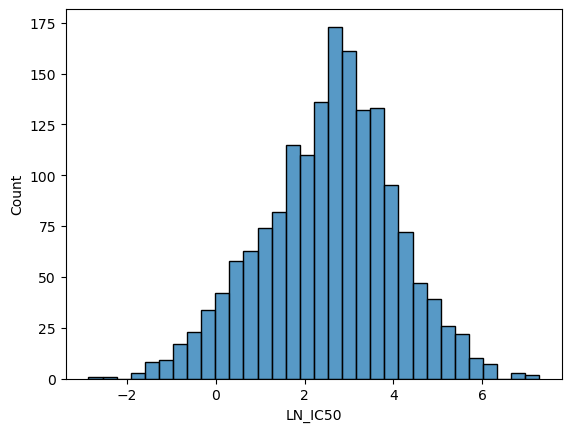

In [51]:
sns.histplot(data = df_ulixertinib, x = 'LN_IC50')# Visualising the distribution of the target variable. 

The target variable (LN_IC50) shows fairly balanced/symmetrical distribution with good variability for modelling. This justifies using a median split for binary classification. 

In [52]:
threshold = df_ulixertinib['LN_IC50'].median() # Defines a variable for the median threshold value of the target variable. 
df_ulixertinib['RESPONSE'] = (df_ulixertinib['LN_IC50'] < threshold).astype(int) # Adds a column to the new Ulixertinib DataFrame with binary values, 1 representing sensitive and 0 representing resistant. This is because a lower IC50 means greater susceptibility to a drug (lower conc. required for 50% inhibition).

In [53]:
df_ulixertinib['RESPONSE'].value_counts() # Verifying this was successful. 2 balanced classes are now present to facilitate the use of supervised classification models.

RESPONSE
0    849
1    849
Name: count, dtype: int64

In [54]:
df_ulixertinib.isnull().sum() # Missing values seem to be relatively sparse with the exception of one column- Cancer Type. This will need to be handled accordingly.

COSMIC_ID                                    0
CELL_LINE_NAME                               0
TCGA_DESC                                    7
DRUG_ID                                      0
DRUG_NAME                                    0
LN_IC50                                      0
AUC                                          0
Z_SCORE                                      0
GDSC Tissue descriptor 1                    64
GDSC Tissue descriptor 2                    64
Cancer Type (matching TCGA label)          361
Microsatellite instability Status (MSI)     82
Screen Medium                               64
Growth Properties                           64
CNA                                         64
Gene Expression                             64
Methylation                                 64
TARGET                                       0
TARGET_PATHWAY                               0
RESPONSE                                     0
dtype: int64

In [55]:
df_ulixertinib.describe() # There seems to be good variation to allow model learning. 

,COSMIC_ID,DRUG_ID,LN_IC50,AUC,Z_SCORE,RESPONSE
count,1.698000e+03,1698.000000,1698.000000,1698.000000,1.698000e+03,1698.000000
mean,9.871812e+05,1968.577150,2.546608,0.894916,2.355713e-09,0.500000
std,2.168702e+05,68.945139,1.501278,0.088952,9.997053e-01,0.500147
min,6.836670e+05,1908.000000,-2.863156,0.309463,-3.730339e+00,0.000000
25%,9.068050e+05,1908.000000,1.609513,0.857600,-6.376582e-01,0.000000
50%,9.097165e+05,1908.000000,2.676538,0.920975,4.431350e-02,0.500000
75%,1.240137e+06,2047.000000,3.551869,0.960949,6.540207e-01,1.000000
max,1.789883e+06,2047.000000,7.283865,0.998020,3.151969e+00,1.000000


In [56]:
df_ulixertinib[['LN_IC50', 'AUC', 'Z_SCORE']].corr() # Testing correlation between LN_IC50, AUC, and Z-Score. High correlation is observed between all pairings as these variables are derived from LN_IC50, justifying dropping AUC and Z-Score columns to prevent data leakage. 

,LN_IC50,AUC,Z_SCORE
LN_IC50,1.000000,0.759049,0.980447
AUC,0.759049,1.000000,0.830963
Z_SCORE,0.980447,0.830963,1.000000


In [57]:
### Dropping Unwanted Columns

df_ulixertinib = df_ulixertinib.drop(columns = ['COSMIC_ID', 'CELL_LINE_NAME', 'DRUG_ID', 'DRUG_NAME', 'LN_IC50', 'AUC', 'Z_SCORE', 'TARGET', 'TARGET_PATHWAY']) # Dropping columns with no predictive value in this context or those which could lead to data leakage.

In [58]:
df_ulixertinib.info() # Verifying the correct columns have been dropped. 

<class 'pandas.core.frame.DataFrame'>
Index: 1698 entries, 177230 to 215749
Data columns (total 11 columns):
 #   Column                                   Non-Null Count  Dtype 
---  ------                                   --------------  ----- 
 0   TCGA_DESC                                1691 non-null   object
 1   GDSC Tissue descriptor 1                 1634 non-null   object
 2   GDSC Tissue descriptor 2                 1634 non-null   object
 3   Cancer Type (matching TCGA label)        1337 non-null   object
 4   Microsatellite instability Status (MSI)  1616 non-null   object
 5   Screen Medium                            1634 non-null   object
 6   Growth Properties                        1634 non-null   object
 7   CNA                                      1634 non-null   object
 8   Gene Expression                          1634 non-null   object
 9   Methylation                              1634 non-null   object
 10  RESPONSE                                 1698 non-null   i

In [59]:
### Handling Missing Values

# Due to a low relative proportion of missing data in the Ulixertinib DataFrame, my initial approach to dealing with missing values is dropping rows/columns containing them. 

df_ulixertinib = df_ulixertinib.drop(columns = ['Cancer Type (matching TCGA label)']) # Removing the column with a high proportion of missing values.
df_ulixertinib = df_ulixertinib.dropna()  # Removing the rows with remaining missing values. 
df_ulixertinib.isnull().sum() # Verifying missing values are now absent. 

TCGA_DESC                                  0
GDSC Tissue descriptor 1                   0
GDSC Tissue descriptor 2                   0
Microsatellite instability Status (MSI)    0
Screen Medium                              0
Growth Properties                          0
CNA                                        0
Gene Expression                            0
Methylation                                0
RESPONSE                                   0
dtype: int64

In [60]:
### Encoding Categorical Variables

df_ulixertinib = pd.get_dummies(df_ulixertinib, drop_first = True) # Categorical variables are one-hot encoded. 
df_ulixertinib.head() # Showing first 5 rows to verify encoding was successful. 

,RESPONSE,TCGA_DESC_ALL,TCGA_DESC_BLCA,TCGA_DESC_BRCA,TCGA_DESC_CESC,TCGA_DESC_CLL,TCGA_DESC_COREAD,TCGA_DESC_DLBC,TCGA_DESC_ESCA,TCGA_DESC_GBM,...,GDSC Tissue descriptor 2_thyroid,GDSC Tissue descriptor 2_urogenital_system_other,GDSC Tissue descriptor 2_uterus,Microsatellite instability Status (MSI)_MSS/MSI-L,Screen Medium_R,Growth Properties_Semi-Adherent,Growth Properties_Suspension,CNA_Y,Gene Expression_Y,Methylation_Y
177230,0,False,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,False,True,True,True
177231,0,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,True,True
177232,0,False,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,False,True,True,True
177233,0,False,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,False,True,True,True
177234,0,False,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,False,True,True,True


In [61]:
df_ulixertinib.shape # Checking general shape of encoded data.

(1609, 110)

In [62]:
### Splitting Features and Target Columns

X = df_ulixertinib.drop(columns = ['RESPONSE'])
y = df_ulixertinib['RESPONSE']

In [63]:
X.shape # Verifying correct shape for X.

(1609, 109)

In [64]:
y.shape # Verifying correct shape for y. 

(1609,)

In [65]:
### Creating Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) # Random state used to ensure repeatability. 

In [66]:
### Scaling Features

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [67]:
### Logistic Regression- Baseline Model

lr = LogisticRegression(max_iter = 1000)
lr.fit(X_train, y_train)



,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [68]:
### Random Forest

rf = RandomForestClassifier(random_state = 42)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [69]:
### Using Models

y_pred_lr = lr.predict(X_test)
y_pred_rf = rf.predict(X_test)

In [70]:
### Evaluating Models

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Logistic Regression Accuracy: 0.7142857142857143
Random Forest Accuracy: 0.7298136645962733


In [71]:
df_ulixertinib['RESPONSE'].value_counts(normalize = True) # Obtaining a baseline accuracy to compare these values to. The almost perfectly balanced classes shows that these accuracy values aren't simply obtained by the models overpredicting one class. 

RESPONSE
1    0.500311
0    0.499689
Name: proportion, dtype: float64

In [72]:
### Confusion Matrices

confusion_matrix(y_test, y_pred_lr)

array([[119,  50],
       [ 42, 111]])

In [73]:
confusion_matrix(y_test, y_pred_rf)

array([[126,  43],
       [ 44, 109]])

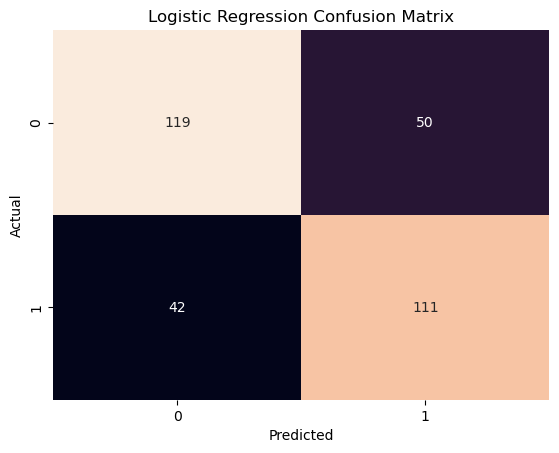

In [74]:
### Generating Better-Looking Confusion Matrices for Paper

matrix_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure()
sns.heatmap(matrix_lr, annot = True, fmt = 'd', cbar = False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

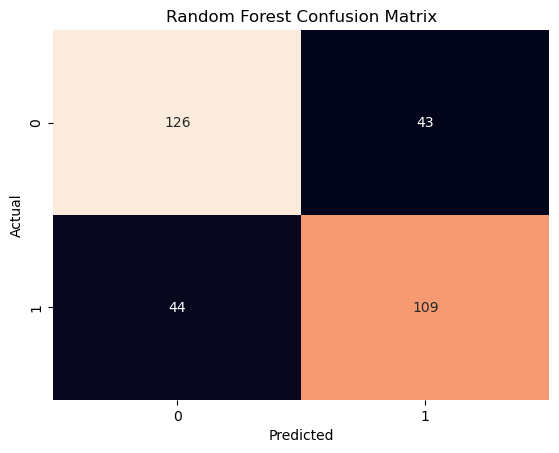

In [75]:
matrix_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure()
sns.heatmap(matrix_rf, annot = True, fmt = 'd', cbar = False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [76]:
### Classification Reports

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.74      0.70      0.72       169
           1       0.69      0.73      0.71       153

    accuracy                           0.71       322
   macro avg       0.71      0.71      0.71       322
weighted avg       0.72      0.71      0.71       322



In [77]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.74      0.75      0.74       169
           1       0.72      0.71      0.71       153

    accuracy                           0.73       322
   macro avg       0.73      0.73      0.73       322
weighted avg       0.73      0.73      0.73       322



In [78]:
### Evaluating Feature Impacts

pd.Series(lr.coef_.ravel(), index = X.columns).abs().sort_values(ascending = False).head(10) # abs is used to convert negative coefficients to positives to remove direction of change and only show magnitude to help with comparison to random forest feature importances.

TCGA_DESC_KIRC                            0.562169
GDSC Tissue descriptor 2_myeloma          0.516188
TCGA_DESC_BRCA                            0.514640
TCGA_DESC_HNSC                            0.494194
GDSC Tissue descriptor 2_head and neck    0.489790
Growth Properties_Semi-Adherent           0.406469
TCGA_DESC_CESC                            0.358554
TCGA_DESC_PRAD                            0.334834
TCGA_DESC_LUAD                            0.326197
GDSC Tissue descriptor 2_leukemia         0.318908
dtype: float64

<Axes: >

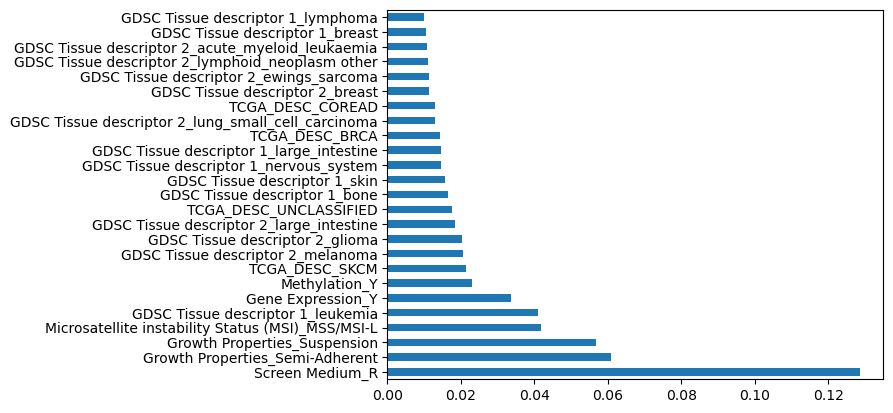

In [79]:
importances = rf.feature_importances_
features = X.columns
feature_importance = pd.Series(importances, index = features)
feature_importance.nlargest(25).plot(kind = 'barh')

In [80]:
### Cross Validation

lr_scores = cross_val_score(lr, X, y, cv = 10) # 10 folds used. 
print(lr_scores.mean(), lr_scores.std())

0.661875 0.05697935413464569


In [81]:
rf_scores = cross_val_score(rf, X, y, cv = 10) # 10 folds used. 
print(rf_scores.mean(), rf_scores.std())

0.6724340062111802 0.052650865145595145


10-fold cross-validation mean accuracy for LR and RF are fairly consistent with accuracy from the single split earlier, showing the accuracy values were not simply dependent on a single split. 

In [82]:
### Paired T Test to Test Significance of Cross Validation Accuracy Difference

_, p_value = ttest_rel(lr_scores, rf_scores)

print("p-value =", p_value)

# Null hypothesis is there is no significant difference between the cross validation accuracies of these logistic regression and random forest models.

p-value = 0.46659402799310135


p > 0.05 therefore the null hypothesis is accepted. 